# P09 — Praktikum DBSCAN: dari data mentah hingga keputusan algoritma
**DAIS32W | Pertemuan 9 **  
Ketercapaian **KK22.1 dan KK23.1** sesuai RPS.

**Tujuan:** melakukan audit dan preprocessing, memverifikasi teori epsilon-neighborhood, mengidentifikasi core/border/noise, menguji sensitivitas `eps`/`min_samples`, membandingkan DBSCAN vs Ward vs K-Means secara adil, dan menyusun alasan pemilihan model.

**Ketentuan:** Jangan gunakan label kelas tersembunyi sebagai fitur atau dasar pemilihan algoritma. Titik noise (`-1`) bukan otomatis data salah. Tuliskan jawaban Anda pada kotak `✍ JAWABAN MAHASISWA`.

**Hubungan P1–P7:** problem framing → jarak/matriks → data quality & EDA → cleaning → scaling → feature selection/PCA → metrik dan interpretasi. Semua akan dibuktikan pada P09.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.cluster import DBSCAN, KMeans, AgglomerativeClustering
from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.decomposition import PCA
from sklearn.metrics import (silhouette_score, davies_bouldin_score, adjusted_rand_score, pairwise_distances)
from sklearn.neighbors import NearestNeighbors
from sklearn.datasets import load_wine, make_moons
SEED = 2026
pd.set_option('display.max_columns', 30)
print('Lingkungan siap: NumPy, pandas, Matplotlib, scikit-learn')

Lingkungan siap: NumPy, pandas, Matplotlib, scikit-learn


## P1  — Dari data sensor mentah ke fitur yang sah
*Kasus pembelajaran sintetis*: koordinat 2D alat ukur (x,y) dalam meter. Data mentah **sengaja mengandung** angka desimal koma, duplikasi, koordinat hilang, dan satu nilai di luar rentang operasional yang didokumentasikan `0≤x≤10` dan `0≤y≤6`.

1. Tentukan unit analisis dan tujuan segmentasi, tanpa label kelas.
2. Temukan masalah yang harus diperbaiki **sebelum** menghitung jarak.
3. Putuskan apakah `sensor_aux` dan `shift` patut dimasukkan dalam jarak spasial. Jelaskan mengapa.

**✍ JAWABAN MAHASISWA P1:**

1. Satu baris di data ini = satu titik pemasangan alat ukur, lengkap dengan posisinya (x, y) dalam meter. Yang mau saya cari: lokasi mana saja yang ngumpul berdekatan, dan lokasi mana yang "nyempil" sendirian jauh dari kelompoknya. Labelnya memang nggak ada, jadi ini murni clustering buat eksplorasi, bukan klasifikasi.

2. Sebelum ngitung jarak, ada beberapa hal yang harus dibereskan dulu dari 15 baris mentah:
   - Titik `K` nulis `x_m` pakai koma (`"3,8"`), jadi satu kolom kebaca sebagai teks. Harus diubah ke 3.8 dulu.
   - Baris `C` (1, 0) muncul dua kali. Kalau dibiarkan, `C` jadi dihitung dobel di N_eps dan bisa "naik pangkat" jadi core padahal nggak seharusnya.
   - `M` nggak punya nilai `y_m`. Saya buang, bukan saya isi, karena nebak posisi fisik alat itu nggak masuk akal.
   - `N` punya x = 999, padahal batas operasionalnya cuma 0–10. Ini jelas salah input, bukan outlier yang wajar.

   Setelah dibersihkan, sisa 12 titik (A–L).

3. `sensor_aux` dan `shift` nggak saya masukkan ke perhitungan jarak. Pertanyaannya kan soal dekat-jauhnya lokasi. `sensor_aux` itu bacaan sensor (angkanya 670–1680, satuannya beda sama meter), jadi kalau ikut dihitung, dia yang bakal "menguasai" jarak. Sementara `shift` cuma info jadwal kerja. Dua kolom ini masih bisa dipakai nanti untuk mendeskripsikan cluster, tapi bukan untuk membentuknya.

In [2]:
def locate_data(name):
    options=[Path('data')/name, Path('../data')/name, Path(name),Path('/mnt/data/P09_DBSCAN_Paket_2026/data')/name]
    for p in options:
        if p.exists():
            return p
    return None

# Fallback memungkinkan notebook contoh manual dijalankan tanpa mengunggah CSV.
from io import StringIO
SAMPLE_RAW = """sample_id,x_m,y_m,sensor_aux,shift
A,0,0,1020,Shift A
B,"0,0","1,0",780,Shift B
C,1,0,1440,Shift A
D,1,1,800,Shift B
E,2,1,1680,Shift A
F,6,0,670,Shift B
G,6,1,1220,Shift A
H,7,0,910,Shift B
I,7,1,1600,Shift A
J,8,1,750,Shift B
K,"3,8",3.8,1310,Shift A
L,9,5,890,Shift B
C,1,0,1440,Shift A
M,5,,1100,Shift A
N,999,0,800,Shift B
"""
source=locate_data('p09_sensor_raw_manual.csv')
raw=pd.read_csv(source) if source is not None else pd.read_csv(StringIO(SAMPLE_RAW))
print('Sumber:',source or 'data tertanam (fallback)')
display(raw)

Sumber: p09_sensor_raw_manual.csv


,sample_id,x_m,y_m,sensor_aux,shift
0,A,0,0.0,1020,Shift A
1,B,0,1.0,780,Shift B
2,C,1,0.0,1440,Shift A
3,D,1,1.0,800,Shift B
4,E,2,1.0,1680,Shift A
5,F,6,0.0,670,Shift B
6,G,6,1.0,1220,Shift A
7,H,7,0.0,910,Shift B
8,I,7,1.0,1600,Shift A
9,J,8,1.0,750,Shift B


In [3]:
def parse_local_number(s):
    return pd.to_numeric(s.astype('string').str.strip().str.replace(',', '.', regex=False), errors='coerce')

prepared=raw.copy()
prepared['x_m']=parse_local_number(prepared['x_m'])
prepared['y_m']=parse_local_number(prepared['y_m'])
print('Jumlah awal:',len(prepared))
print('Duplikasi seluruh baris:',int(prepared.duplicated().sum()))
print('Hilang koordinat:',int(prepared[['x_m','y_m']].isna().any(axis=1).sum()))
valid_domain=prepared['x_m'].between(0,10)&prepared['y_m'].between(0,6)
print('Di luar domain 0≤x≤10, 0≤y≤6 (hanya baris koordinat lengkap):',int((~valid_domain & prepared[['x_m','y_m']].notna().all(axis=1)).sum()))
clean=(prepared.drop_duplicates()
               .dropna(subset=['x_m','y_m'])
               .loc[lambda d: d['x_m'].between(0,10) & d['y_m'].between(0,6)]
               .sort_values('sample_id').reset_index(drop=True))
assert len(clean)==12, 'Audit bersih seharusnya 12 titik A–L.'
print('Jumlah sesudah cleaning:',len(clean))
display(clean[['sample_id','x_m','y_m','sensor_aux','shift']])

Jumlah awal: 15
Duplikasi seluruh baris: 1
Hilang koordinat: 1
Di luar domain 0≤x≤10, 0≤y≤6 (hanya baris koordinat lengkap): 1
Jumlah sesudah cleaning: 12


,sample_id,x_m,y_m,sensor_aux,shift
0,A,0.0,0.0,1020,Shift A
1,B,0.0,1.0,780,Shift B
2,C,1.0,0.0,1440,Shift A
3,D,1.0,1.0,800,Shift B
4,E,2.0,1.0,1680,Shift A
5,F,6.0,0.0,670,Shift B
6,G,6.0,1.0,1220,Shift A
7,H,7.0,0.0,910,Shift B
8,I,7.0,1.0,1600,Shift A
9,J,8.0,1.0,750,Shift B


## P2  — EDA: skala, outlier valid, jarak dan fitur
*Hipotesis sebelum kode:* jika `sensor_aux` (berkisar ratusan–ribuan) dimasukkan bersama koordinat (0–10 m) tanpa pertimbangan, jarak dapat didominasi fitur yang tidak relevan.

**Jalankan** statistik, histogram, scatter dan korelasi. **JAWAB:** mana nilai salah (M/N) dan mana titik jarang tetapi masih sah (K/L)?

,x_m,y_m,sensor_aux
count,12.0,12.0,12.00
mean,4.23,1.23,1089.17
std,3.31,1.57,349.74
min,0.0,0.0,670.00
25%,1.0,0.0,795.00
50%,4.9,1.0,965.00
75%,7.0,1.0,1342.50
max,9.0,5.0,1680.00


Missing dalam clean: {'x_m': 0, 'y_m': 0}
Korelasi numerik:


,x_m,y_m,sensor_aux
x_m,1.000,0.363,-0.144
y_m,0.363,1.000,0.023
sensor_aux,-0.144,0.023,1.000


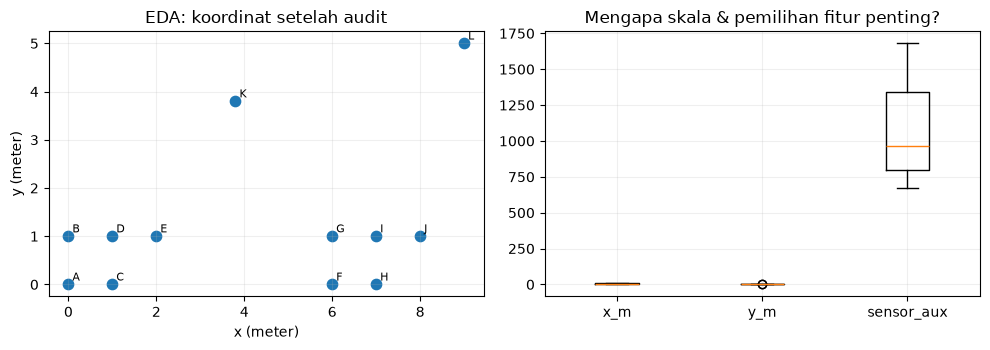

In [4]:
display(clean[['x_m','y_m','sensor_aux']].describe().round(2))
print('Missing dalam clean:',clean[['x_m','y_m']].isna().sum().to_dict())
print('Korelasi numerik:');display(clean[['x_m','y_m','sensor_aux']].corr().round(3))
fig,axs=plt.subplots(1,2,figsize=(10,3.6))
axs[0].scatter(clean.x_m,clean.y_m,s=55)
for _,r in clean.iterrows():axs[0].annotate(r.sample_id,(r.x_m+.09,r.y_m+.08),fontsize=8)
axs[0].set(xlabel='x (meter)',ylabel='y (meter)',title='EDA: koordinat setelah audit');axs[0].grid(alpha=.2)
axs[1].boxplot([clean.x_m,clean.y_m,clean.sensor_aux],tick_labels=['x_m','y_m','sensor_aux'])
axs[1].set_title('Mengapa skala & pemilihan fitur penting?');axs[1].grid(alpha=.2)
plt.tight_layout();plt.show()

**✍ JAWABAN MAHASISWA P2 (minimal 4 temuan bernilai angka):**

1. Dari 15 baris mentah ada 1 duplikat (`C`), 1 koordinat kosong (`M`), dan 1 nilai di luar domain (`N`, x = 999). Sisanya 12 titik, dan setelah itu sudah nggak ada missing di x maupun y.
2. Skalanya beda jauh. x ada di 0–9 m (std 3.31) dan y di 0–5 m (std 1.57), sedangkan `sensor_aux` di 670–1680 (std 349.74). Rentang `sensor_aux` kira-kira 112× rentang x, jadi kalau digabung mentah-mentah, jaraknya hampir pasti cuma ngikutin `sensor_aux`.
3. Korelasinya juga mendukung keputusan ini: r(x, sensor_aux) = −0.144 dan r(y, sensor_aux) = 0.023, alias hampir nol. Artinya bacaan sensor ini praktis nggak ada hubungannya dengan posisi. Antara x dan y sendiri r = 0.363.
4. Soal mana yang salah dan mana yang cuma jarang: `M` (y kosong) dan `N` (x = 999) itu nilai yang memang salah, jadi dibuang. Beda dengan `K` (3.8, 3.8) dan `L` (9, 5), yang masih di dalam domain jadi posisinya sah. Mereka cuma jauh dari yang lain: tetangga terdekat K itu E (3.33 m), dan tetangga terdekat L itu J (4.12 m), padahal titik-titik lain rata-rata cuma 1 m dari tetangganya. Jadi K dan L tetap saya simpan dan biar DBSCAN yang menilai.
5. Dari scatter-nya kelihatan ada dua gerombol: A–E di kiri bawah dan F–J di kanan bawah, dengan jarak antargerombol sekitar 4.1 m (E–F = 4.123 m).

**Keputusan fitur:** Untuk pertanyaan “kelompok lokasi sensor yang saling berdekatan”, kita menggunakan **hanya x_m dan y_m**. `sensor_aux` tidak otomatis relevan dan `shift` bukan koordinat; jangan menambah fitur hanya karena tersedia.

## P3  — Bukti teori: jarak, tetangga, core, border dan noise
Parameter manual: **`eps=1.1 meter`, `min_samples=3` (termasuk titik itu sendiri)**.

Definisi `N_eps(p) = {q: d(p,q) ≤ eps}`. Titik **core** jika `|N_eps(p)| ≥ min_samples`; **border** jika bukan core tetapi memiliki tetangga core; **noise** jika keduanya tidak terpenuhi. Label `-1` menandakan noise.

**Tugas manual:** hitung d(A,B), d(A,D), d(D,E), d(I,J); tentukan tetangga A,D,E,K. **Jalankan** kode dan cocokkan dengan jawaban manual.

**✍ JAWABAN MAHASISWA P3:**

Pakai rumus Euclidean d(p,q) = √((x_p−x_q)² + (y_p−y_q)²):
- d(A,B) = √(0² + 1²) = 1.000, masih ≤ 1.1, jadi tetangga.
- d(A,D) = √(1² + 1²) = √2 ≈ 1.414. Ini lebih dari 1.1, jadi walaupun "kelihatan dekat", diagonalnya nggak masuk.
- d(D,E) = √(1² + 0²) = 1.000, tetangga.
- d(I,J) = √(1² + 0²) = 1.000, tetangga.

Tetangga dalam eps = 1.1 (termasuk dirinya sendiri):
- A → {A, B, C}, ada 3 titik, cukup untuk min_samples = 3, jadi core.
- D → {B, C, D, E}, ada 4 titik, jadi core.
- E → {D, E}, cuma 2. Nggak cukup jadi core, tapi karena D (core) ada di dekatnya, E jadi border.
- K → {K} doang. Titik terdekatnya E, itu pun 3.33 m, jadi noise.

Setelah kodenya dijalankan, hasilnya sama persis dengan hitungan manual: core = A, B, C, D, F, G, H, I; border = E, J; noise = K, L.

In [5]:
X=clean[['x_m','y_m']].to_numpy(float)
D=pairwise_distances(X,metric='euclidean')
names=clean.sample_id.tolist()
print('Contoh jarak (meter)')
for a,b in [('A','B'),('A','D'),('D','E'),('I','J')]:
    i,j=names.index(a),names.index(b)
    print(f'{a}–{b}: {D[i,j]:.4f}')
eps=1.1; min_samples=3
near=D <= eps + 1e-10
ncount=near.sum(axis=1)
core=ncount>=min_samples
border=~core & (near[:,core].any(axis=1))
status=np.where(core,'CORE',np.where(border,'BORDER','NOISE'))
manual=pd.DataFrame({'titik':names,'N_eps':[[names[j] for j in np.flatnonzero(near[i])] for i in range(len(names))],
                     'jumlah_termasuk_diri':ncount,'status':status})
display(manual)
print('Core:',manual.loc[manual.status=='CORE','titik'].tolist())
print('Border:',manual.loc[manual.status=='BORDER','titik'].tolist())
print('Noise:',manual.loc[manual.status=='NOISE','titik'].tolist())

Contoh jarak (meter)
A–B: 1.0000
A–D: 1.4142
D–E: 1.0000
I–J: 1.0000


,titik,N_eps,jumlah_termasuk_diri,status
0,A,"[A, B, C]",3,CORE
1,B,"[A, B, D]",3,CORE
2,C,"[A, C, D]",3,CORE
3,D,"[B, C, D, E]",4,CORE
4,E,"[D, E]",2,BORDER
5,F,"[F, G, H]",3,CORE
6,G,"[F, G, I]",3,CORE
7,H,"[F, H, I]",3,CORE
8,I,"[G, H, I, J]",4,CORE
9,J,"[I, J]",2,BORDER


Core: ['A', 'B', 'C', 'D', 'F', 'G', 'H', 'I']
Border: ['E', 'J']
Noise: ['K', 'L']


status        BORDER  CORE  NOISE
dbscan_label                     
-1                 0     0      2
 0                 1     4      0
 1                 1     4      0


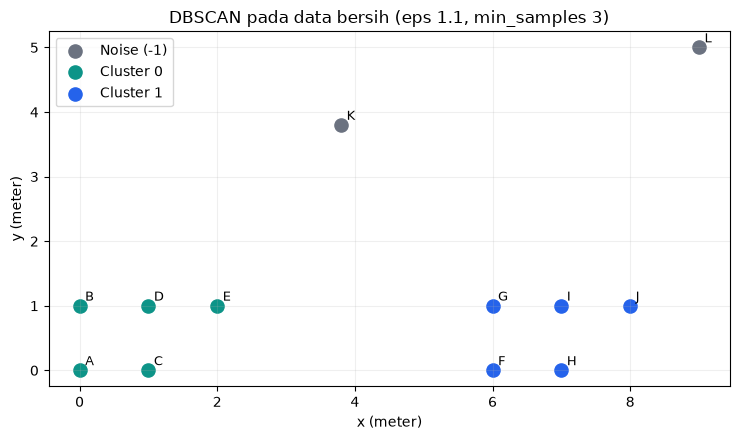

In [6]:
db=DBSCAN(eps=eps,min_samples=min_samples,metric='euclidean').fit(X)
clean['dbscan_label']=db.labels_
assert (np.isin(db.labels_,[-1,0,1])).all()
print(pd.crosstab(clean.dbscan_label,manual.status))
fig,ax=plt.subplots(figsize=(7.5,4.5))
colors={-1:'#6b7280',0:'#0d9488',1:'#2563eb'}
for lab in sorted(clean.dbscan_label.unique()):
    mask=clean.dbscan_label==lab
    ax.scatter(clean.loc[mask,'x_m'],clean.loc[mask,'y_m'],s=90,c=colors.get(lab),label=f'Cluster {lab}' if lab!=-1 else 'Noise (-1)')
for _,r in clean.iterrows():ax.annotate(r.sample_id,(r.x_m+.08,r.y_m+.08),fontsize=9)
ax.set(xlabel='x (meter)',ylabel='y (meter)',title='DBSCAN pada data bersih (eps 1.1, min_samples 3)')
ax.legend();ax.grid(alpha=.2);plt.tight_layout();plt.show()

**✍ JAWABAN MAHASISWA P3 — Jelaskan urutan *cluster expansion*.** Mulai dari A lalu F. Jelaskan mengapa E dan J tetap bisa masuk cluster walau bukan core, dan mengapa K dan L tetap noise.

Prosesnya kira-kira begini. DBSCAN mulai dari A, yang ternyata core, jadi dibuat cluster 0. Tetangganya, B dan C, ikut masuk. B dan C juga core, jadi mereka "menarik" D. D juga core, dan dari situ E ikut masuk. Nah, E cuma punya 2 titik di sekitarnya, jadi dia masuk cluster sebagai border tapi nggak bisa narik titik lain lagi. Ekspansinya berhenti di situ, dan cluster 0 = {A, B, C, D, E}.

Lalu DBSCAN lanjut ke titik core berikutnya yang belum dikunjungi, yaitu F, dan bikin cluster 1. F narik G dan H, keduanya narik I, lalu I (yang punya 4 tetangga) narik J. J sama nasibnya dengan E: masuk sebagai border. Jadi cluster 1 = {F, G, H, I, J}.

E dan J tetap bisa masuk cluster karena syaratnya bukan "harus core", tapi cukup bisa dijangkau dari core. E cuma 1 m dari D, J cuma 1 m dari I.

K dan L lain cerita. Di radius 1.1 m mereka cuma berisi diri sendiri, dan nggak ada core yang cukup dekat (K–E 3.33 m, L–J 4.12 m). Jadi keduanya dapat label −1. Crosstab-nya juga cocok: tiap cluster isinya 4 core + 1 border, dan label −1 isinya 2 titik noise.

## P4  — Sensitivitas `eps` dan `min_samples`
Perhatikan: perubahan `eps`/`min_samples` dapat mengubah jumlah core, border, noise, cluster. Analisis **k-distance** mengusulkan kandidat `eps`, bukan memberikan nilai pasti.

**Ablation A:** ubah hanya `eps` sambil mempertahankan `min_samples=3`. **Ablation B:** ubah hanya `min_samples` sambil `eps=1.1`.

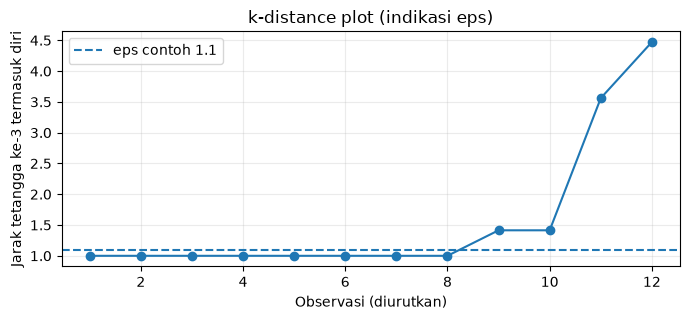

In [7]:
nearest=NearestNeighbors(n_neighbors=3).fit(X)
d3,_=nearest.kneighbors(X)
# Kolom ketiga = 3-nearest termasuk diri sendiri, sesuai min_samples=3
third=np.sort(d3[:,-1])
fig,ax=plt.subplots(figsize=(7,3.3));ax.plot(np.arange(1,len(third)+1),third,marker='o')
ax.axhline(1.1,linestyle='--',label='eps contoh 1.1');ax.set(xlabel='Observasi (diurutkan)',ylabel='Jarak tetangga ke-3 termasuk diri',title='k-distance plot (indikasi eps)')
ax.legend();ax.grid(alpha=.25);plt.tight_layout();plt.show()

In [8]:
def cluster_diagnostics(X,labels,method=''):
    X=np.asarray(X,dtype=float); y=np.asarray(labels)
    keep=y!=-1; actual_clusters=sorted(set(y[keep])); ncl=len(actual_clusters)
    result={'method':method,'n_clusters':ncl,'noise_n':int((~keep).sum()),'noise_pct':round(100*(~keep).mean(),1),
            'coverage_pct':round(100*keep.mean(),1),'min_cluster':int(min((y==v).sum() for v in actual_clusters)) if ncl else 0}
    # Silhouette DBI untuk DBSCAN: hanya titik bukan noise; selalu laporkan cakupannya.
    if 2<=ncl<keep.sum():
        result['silhouette_retained']=round(float(silhouette_score(X[keep],y[keep])),4)
        result['DBI_retained']=round(float(davies_bouldin_score(X[keep],y[keep])),4)
    else:result['silhouette_retained']=np.nan; result['DBI_retained']=np.nan
    return result

def compare_on_retained_subset(X,db_labels,other_labels):
    # Adil pada himpunan titik YANG SAMA, tidak memakai ground-truth tersembunyi.
    keep=np.asarray(db_labels)!=-1
    rows=[]
    for name,y in [('DBSCAN',db_labels),('pembanding',other_labels)]:
        y=np.asarray(y)[keep]; unique=np.unique(y)
        value=float(silhouette_score(np.asarray(X)[keep],y)) if 1<len(unique)<len(y) else np.nan
        rows.append({'model':name,'n_evaluated':int(keep.sum()),'silhouette_same_subset':round(value,4)})
    return pd.DataFrame(rows)

records=[]
for e,ms in [(0.9,3),(1.1,3),(1.5,3),(2.5,3),(1.1,4),(1.1,2)]:
    lab=DBSCAN(eps=e,min_samples=ms).fit_predict(X)
    records.append({'eps':e,'min_samples':ms,**cluster_diagnostics(X,lab,method='DBSCAN')})
sweep=pd.DataFrame(records)
display(sweep[['eps','min_samples','n_clusters','noise_n','coverage_pct','min_cluster','silhouette_retained','DBI_retained']])

,eps,min_samples,n_clusters,noise_n,coverage_pct,min_cluster,silhouette_retained,DBI_retained
0,0.9,3,0,12,0.0,0,NaN,NaN
1,1.1,3,2,2,83.3,5,0.7730,0.2826
2,1.5,3,2,2,83.3,5,0.7730,0.2826
3,2.5,3,2,2,83.3,5,0.7730,0.2826
4,1.1,4,2,4,66.7,4,0.7802,0.2551
5,1.1,2,2,2,83.3,5,0.7730,0.2826


**✍ JAWABAN MAHASISWA P4:** Untuk dua baris yang hanya berbeda satu parameter, jelaskan perubahan hasil dan hubungan dengan perhitungan neighborhood. Bila seluruh titik noise atau hanya satu cluster, mengapa Silhouette tidak boleh dipaksakan?

Dari k-distance plot, jarak ke tetangga ke-3 untuk 8 titik itu 1.0, untuk E dan J 1.414, lalu tiba-tiba loncat ke 3.56 (K) dan 4.47 (L). "Siku"-nya ada di antara 1.414 dan 3.56, jadi eps sekitar 1.0–2.5 masih masuk akal. eps = 1.1 ada di rentang itu, tapi tetap cuma kandidat, bukan angka pasti.

Ablation A (eps diubah, min_samples tetap 3):
- eps 1.1 → 0.9: hasilnya langsung ambruk, 0 cluster dan semua 12 titik jadi noise (coverage 0%). Wajar, karena jarak tetangga terdekat semua titik minimal 1.0. Dengan eps 0.9, nggak ada yang punya tetangga, jadi nggak ada core sama sekali.
- eps 1.1 → 1.5 atau 2.5: hasilnya sama persis (2 cluster, K dan L noise, silhouette 0.773). Di eps 1.5, E dan J sebenarnya sudah jadi core karena diagonal 1.414 ikut masuk, tapi anggota cluster-nya tetap sama. Dua gerombol juga nggak nyambung karena jaraknya 4.12 m, dan K/L tetap sendirian karena tetangga terdekatnya di atas 2.5 m. Jadi hasilnya cukup stabil.

Ablation B (min_samples diubah, eps tetap 1.1):
- min_samples 3 → 4: noise naik dari 2 jadi 4 (coverage 66.7%). Sekarang yang memenuhi syarat core cuma D dan I (masing-masing 4 tetangga). A cuma punya 3 tetangga, dan jaraknya ke D 1.414 (lebih dari eps), jadi A ikut jadi noise. F juga begitu. Silhouette-nya memang naik sedikit (0.7802 vs 0.7730), tapi itu karena lebih banyak titik yang dibuang, bukan karena clustering-nya lebih bagus.
- min_samples 3 → 2: hasil sama dengan baseline. E dan J jadi core, tapi K dan L tetap noise karena memang nggak punya tetangga sama sekali dalam 1.1 m.

Soal Silhouette: rumusnya s(i) = (b − a)/max(a, b), dan b itu jarak ke cluster lain. Kalau semuanya noise (seperti eps 0.9) atau cuma ada 1 cluster, b-nya nggak ada, jadi skornya nggak bisa dihitung (`NaN`). Noise juga nggak bisa dianggap "cluster −1", karena noise memang bukan kelompok. Makanya di tabel, silhouette selalu saya baca bareng `coverage_pct`.

## P5  — Bandingkan DBSCAN, Hierarchical Ward dan K-Means
**Tujuan berbeda:** K-Means mencari centroid kompak; Ward membangun hierarki (dendrogram); DBSCAN mencari wilayah padat dan boleh meninggalkan noise. Tidak ada “pemenang universal”.

**Aturan adil:** samakan objek dan fitur. Untuk DBSCAN, Silhouette/DBI **dihitung pada titik retained (bukan noise)** dan laporkan `coverage_pct`. Jika ingin membandingkan nilainya dengan K-Means/Ward, hitung ulang model pembanding pada **subset retained yang sama**, selain hasil keseluruhan.

**✍ Sebelum menjalankan:** metode apa yang paling sesuai untuk tujuan menandai lokasi yang berada di luar kelompok padat?

Menurut saya DBSCAN, karena cuma dia yang punya "tempat" untuk titik yang nggak masuk kelompok mana pun (label −1). K-Means dan Ward selalu maksa semua titik masuk ke salah satu cluster, jadi K dan L bakal ditempelkan ke kelompok terdekat walaupun jaraknya lebih dari 3 m dari titik mana pun.

In [9]:
comp=[];labels_map={}
for method in ['KMeans','Ward','DBSCAN']:
    if method=='KMeans':lab=KMeans(n_clusters=2,random_state=SEED,n_init=20).fit_predict(X)
    elif method=='Ward':lab=AgglomerativeClustering(n_clusters=2,linkage='ward').fit_predict(X)
    else:lab=DBSCAN(eps=1.1,min_samples=3).fit_predict(X)
    labels_map[method]=lab
    comp.append(cluster_diagnostics(X,lab,method))
display(pd.DataFrame(comp))
print('Perbandingan Silhouette pada SUBSET observasi retained oleh DBSCAN:')
sub=labels_map['DBSCAN']!=-1
rows=[]
for name,lab in labels_map.items():
    v=lab[sub]
    rows.append({'metode':name,'n_titik_sama':sum(sub),'silhouette_sama':round(float(silhouette_score(X[sub],v)),4) if 2<=len(set(v))<sum(sub) else np.nan})
display(pd.DataFrame(rows))

,method,n_clusters,noise_n,noise_pct,coverage_pct,min_cluster,silhouette_retained,DBI_retained
0,KMeans,2,0,0.0,100.0,5,0.6047,0.4844
1,Ward,2,0,0.0,100.0,5,0.6047,0.4844
2,DBSCAN,2,2,16.7,83.3,5,0.7730,0.2826


Perbandingan Silhouette pada SUBSET observasi retained oleh DBSCAN:


,metode,n_titik_sama,silhouette_sama
0,KMeans,10,0.773
1,Ward,10,0.773
2,DBSCAN,10,0.773


**✍ JAWABAN MAHASISWA P5:** Bandingkan tujuan, keluaran (noise / centroid / dendrogram), metrik dan cakupan. Apakah “Silhouette DBSCAN tertinggi” otomatis membuktikan DBSCAN terbaik ketika sebagian titik dibuang? Jelaskan.

| | K-Means (k=2) | Ward (k=2) | DBSCAN (eps 1.1, ms 3) |
|---|---|---|---|
| Tujuan | centroid kompak | hierarki/dendrogram | wilayah padat + noise |
| Keluaran | 2 centroid: (0.80, 0.60) & (6.69, 1.69) | 2 cabang | 2 cluster + 2 noise |
| Cakupan | 100% (12) | 100% (12) | 83.3% (10) |
| Silhouette | 0.6047 | 0.6047 | 0.7730 (retained) |
| DBI | 0.4844 | 0.4844 | 0.2826 (retained) |
| Silhouette di 10 titik yang sama | 0.773 | 0.773 | 0.773 |

Sekilas DBSCAN kelihatan menang (0.773 vs 0.605), tapi menurut saya ini perbandingan yang nggak adil, karena DBSCAN cuma dinilai di 10 titik sedangkan K-Means dan Ward di 12 titik. Begitu ketiganya dihitung di 10 titik yang sama, skornya ternyata identik, 0.773. Jadi selisihnya murni karena DBSCAN membuang K dan L. K-Means dan Ward memasukkan K dan L ke cluster F–J (centroid-nya sampai ketarik ke (6.69, 1.69)), dan dua titik jauh itulah yang menurunkan silhouette mereka.

Pelajarannya: skor internal gampang "didongkrak" dengan membuang titik yang susah, jadi silhouette harus selalu dibaca bareng coverage. Yang lebih menentukan justru tujuannya. Kalau mau menandai lokasi yang terpencil, DBSCAN cocok karena punya label noise. Tapi kalau setiap lokasi wajib punya kelompok (misalnya untuk bagi rute teknisi), K-Means/Ward yang cakupannya 100% malah lebih pas.

## P6  — Hubungan langsung dengan preprocessing P1–P7
Uji pengaruh tiga faktor dengan eksperimen terkontrol:

- Data bermasalah vs data bersih (duplikasi, missing, nilai mustahil);
- Fitur koordinat saja vs menambah fitur sensor_aux yang skalanya jauh lebih besar;
- Koordinat tanpa scaling vs StandardScaler pada data *yang sama*.

**Jangan memaksa kesimpulan** bahwa StandardScaler selalu wajib: x dan y **sudah sama-sama dalam meter**, sehingga scaling bisa mengubah makna geometri jika variasi kedua sumbu berbeda. Tentukan berdasar tujuan.

**✍ Hipotesis sebelum kode:**

Dugaan saya sebelum menjalankan kode:
(a) Kalau `sensor_aux` mentah ikut masuk, semua jarak bakal jauh di atas 1.1, jadi kemungkinan semua titik jadi noise.
(b) StandardScaler di XY bakal mengubah satuan dari meter jadi "satuan std", jadi eps = 1.1 sudah nggak berarti 1.1 m lagi. Gerombolnya mungkin masih kelihatan, tapi silhouette-nya bakal berubah.
(c) Nilai x = 999 bakal "membajak" salah satu centroid K-Means.

In [10]:
# Bandingkan perubahan yang sah; ini eksperimen sensitivitas fitur, bukan tuning bebas.
cases={'XY asli (meter)':X,
       'XY + sensor_aux mentah':clean[['x_m','y_m','sensor_aux']].to_numpy(float),
       'XY standar':StandardScaler().fit_transform(X),
       'XY + sensor_aux standar':StandardScaler().fit_transform(clean[['x_m','y_m','sensor_aux']])}
rows=[]
for title,XX in cases.items():
    # eps=1.1 meter hanya bermakna dalam ruang XY asli. Untuk ruang lain eps wajib diestimasi ulang;
    # disini sengaja tetap 1.1 agar terlihat bahwa skala & ruang mengubah arti eps.
    yy=DBSCAN(eps=1.1,min_samples=3).fit_predict(XX)
    rows.append({'fitur':title,**cluster_diagnostics(XX,yy)})
display(pd.DataFrame(rows)[['fitur','n_clusters','noise_n','coverage_pct','silhouette_retained']])
# Tinjau dampak nilai tidak sah terhadap centroid K-Means (tanpa mempertaruhkan data utama)
validnum=prepared.drop_duplicates().dropna(subset=['x_m','y_m'])
badX=validnum[['x_m','y_m']].to_numpy(float)
ref_km=KMeans(n_clusters=2,n_init=20,random_state=SEED).fit(X)
bad_km=KMeans(n_clusters=2,n_init=20,random_state=SEED).fit(badX)
print('Centroid K-Means pada CLEAN:\n',np.round(ref_km.cluster_centers_,2))
print('Centroid K-Means jika nilai x=999 ikut masuk:\n',np.round(bad_km.cluster_centers_,2))

,fitur,n_clusters,noise_n,coverage_pct,silhouette_retained
0,XY asli (meter),2,2,83.3,0.7730
1,XY + sensor_aux mentah,0,12,0.0,NaN
2,XY standar,2,2,83.3,0.6862
3,XY + sensor_aux standar,2,6,50.0,0.6332


Centroid K-Means pada CLEAN:
 [[0.8  0.6 ]
 [6.69 1.69]]
Centroid K-Means jika nilai x=999 ikut masuk:
 [[  4.23   1.23]
 [999.     0.  ]]


**✍ JAWABAN MAHASISWA P6 (minimal 3 bukti angka):**
1. Dampak nilai tidak sah/duplikasi/missing dibandingkan setelah dibersihkan.
2. Dampak skala dan fitur yang tidak relevan terhadap arti “dekat”.
3. Mengapa eps=1.1 meter tidak dapat dipindahkan begitu saja ke ruang StandardScaler atau PCA.
4. Satu hubungan eksplisit ke materi P1–P7.

**Jawaban:**

1. **Data kotor vs data bersih.** Di data bersih, centroid K-Means (k = 2) ada di (0.80, 0.60) dan (6.69, 1.69), cocok dengan dua gerombol yang kelihatan di scatter. Tapi kalau titik N (x = 999) nggak dibuang, centroid-nya jadi (4.23, 1.23) dan (999, 0). Satu cluster habis cuma buat satu titik salah input, dan 12 titik asli dijejalkan jadi satu kelompok. Dugaan (c) terbukti. Duplikat C juga bakal bikin C kehitung dobel di N_eps, sedangkan M malah nggak bisa dihitung jaraknya sama sekali.

2. **Skala dan fitur yang nggak relevan.** Dengan eps 1.1 dan min_samples 3:
   - XY asli: 2 cluster, 2 noise, coverage 83.3%, silhouette 0.773.
   - XY + `sensor_aux` mentah: semua 12 titik jadi noise (coverage 0%), sesuai dugaan (a). Selisih `sensor_aux` antartitik bisa puluhan sampai ratusan, jadi arti "dekat" berubah dari "lokasinya berdekatan" jadi "bacaan sensornya mirip".
   - XY + `sensor_aux` distandarkan: noise jadi 6 (coverage 50%), yaitu C, E, G, I, K, L. Yang bikin saya kaget, C, E, G, dan I itu sebenarnya ada di tengah gerombol yang rapat, dan keempatnya Shift A dengan `sensor_aux` tinggi (1220–1680). Jadi fitur yang nggak relevan bisa bikin lokasi yang jelas-jelas berdekatan malah dicap noise.

3. **Kenapa eps 1.1 m nggak bisa dipakai begitu saja setelah scaling.** StandardScaler membagi x dengan std ≈ 3.17 dan y dengan std ≈ 1.50. Jadi satu satuan di ruang baru sudah bukan 1 meter lagi, dan sumbu y "ketarik" sekitar 2.1× dibanding x. Di data ini kebetulan anggota cluster-nya masih sama, tapi silhouette-nya turun ke 0.686 (dari 0.773) karena bentuk ruangnya berubah. Kalau pindah ke ruang StandardScaler atau PCA, eps harus dicari ulang lewat k-distance di ruang itu. Karena x dan y di sini sudah sama-sama meter, menurut saya lebih masuk akal pakai XY asli tanpa scaling.

4. **Hubungannya dengan P1–P7.** Data quality dan cleaning (P3–P4) yang mencegah munculnya centroid (999, 0). Konsep jarak/matriks (P2) menjelaskan kenapa N_eps dan eps bergantung pada satuan. Untuk scaling (P5), ternyata nggak selalu wajib kalau satuannya sudah sama, beda dengan Wine di P08 yang rasio rentang fiturnya sampai 2645×. Feature selection (P6) kelihatan dari `sensor_aux` yang malah merusak hasil. Dan dari sisi metrik (P7), silhouette harus selalu dibaca bareng coverage.

## P7  — Transfer intuisi dan laporan mini
Kasus tambahan bentuk *dua bulan sabit*: dibuat secara **sintetis**, bukan Wine. Tujuannya menunjukkan bahwa cluster non-konveks bisa merugikan pendekatan centroid/Ward. **Label generator tidak digunakan** untuk training/tuning ataupun penilaian internal.

Kesimpulan wajib: **kapan memilih** K-Means, Ward, DBSCAN; kapan DBSCAN juga gagal (densitas bervariasi, eps tidak cocok, dimensi tinggi, semua noise/satu cluster).


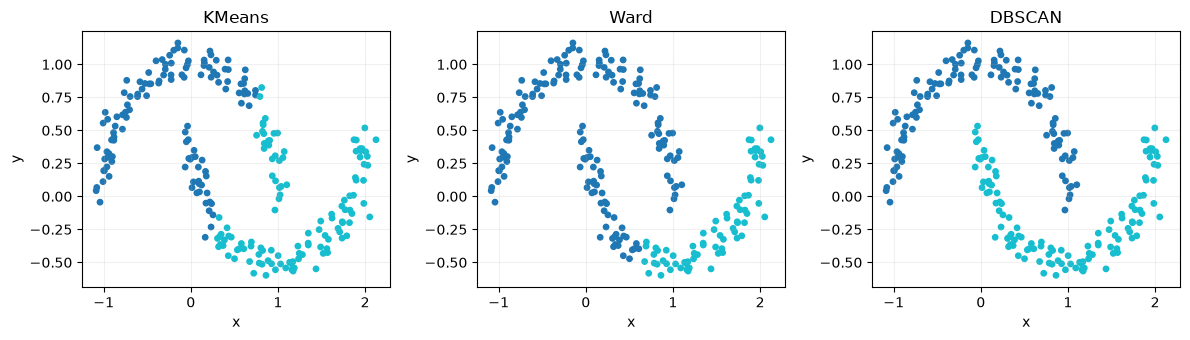

,method,n_clusters,noise_n,noise_pct,coverage_pct,min_cluster,silhouette_retained,DBI_retained
0,KMeans,2,0,0.0,100.0,119,0.4861,0.7835
1,Ward,2,0,0.0,100.0,74,0.4355,0.7714
2,DBSCAN,2,0,0.0,100.0,120,0.3277,1.1643


In [11]:
curve,_=make_moons(n_samples=240,noise=.07,random_state=SEED)
models={'KMeans':KMeans(n_clusters=2,n_init=20,random_state=SEED).fit_predict(curve),
        'Ward':AgglomerativeClustering(n_clusters=2,linkage='ward').fit_predict(curve),
        'DBSCAN':DBSCAN(eps=.23,min_samples=5).fit_predict(curve)}
fig,axs=plt.subplots(1,3,figsize=(12,3.5))
for ax,(name,yy) in zip(axs,models.items()):
    ax.scatter(curve[:,0],curve[:,1],c=yy,cmap='tab10',s=15)
    ax.set(title=name,xlabel='x',ylabel='y');ax.grid(alpha=.18)
plt.tight_layout();plt.show()
display(pd.DataFrame([cluster_diagnostics(curve,y,name) for name,y in models.items()]))

**✍ JAWABAN MAHASISWA P7 — Interpretasi dua bulan sabit & kesimpulan:**

Dari plotnya kelihatan jelas: DBSCAN (eps 0.23, min_samples 5) bisa ngikutin dua lengkungan bulan sabit tanpa noise sama sekali. K-Means dan Ward malah memotong data dengan garis yang kurang lebih lurus, jadi ujung masing-masing bulan nyasar ke cluster bulan yang lain. Yang menarik, silhouette-nya justru bilang sebaliknya: K-Means 0.486, Ward 0.436, DBSCAN cuma 0.328 (DBI-nya 0.78 / 0.77 / 1.16). Ini karena silhouette dan DBI pada dasarnya "suka" cluster yang bulat dan kompak, jadi cluster yang melengkung dan memanjang otomatis dapat nilai jelek. Jadi metrik internal nggak bisa dijadikan satu-satunya patokan, dan bentuk cluster yang diharapkan juga harus dipertimbangkan. Label dari `make_moons` sama sekali nggak saya pakai. Penilaian bentuknya murni dari lihat plot.

Kapan pakai yang mana:
- **K-Means** cocok kalau cluster-nya kira-kira bulat dan ukurannya mirip, jumlah k bisa ditentukan, kita butuh centroid untuk `predict` data baru, atau datanya besar (komputasinya ringan, O(n·k)).
- **Ward** cocok kalau datanya kecil sampai sedang dan kita ingin melihat struktur bertingkat lewat dendrogram, atau masih ragu dengan k. Tapi dia juga lebih suka bentuk cembung, dan memorinya O(n²).
- **DBSCAN** cocok kalau bentuk cluster-nya bebas, jumlah cluster belum tahu, dan kita memang butuh menandai noise (seperti kasus sensor ini). Syaratnya, jarak di ruang fiturnya harus punya arti, misalnya dalam meter.

DBSCAN juga bisa gagal, misalnya:
1. Kalau kepadatan antar cluster beda-beda. Satu eps nggak bisa cocok untuk gerombol yang rapat sekaligus yang renggang.
2. Kalau eps-nya salah pilih. Di data sensor, eps 0.9 bikin semua titik jadi noise, sebaliknya eps yang terlalu besar bakal menyatukan semuanya.
3. Di dimensi tinggi, jarak antartitik jadi mirip-mirip semua, jadi eps susah ditentukan.
4. Kalau hasilnya semua noise atau cuma 1 cluster, silhouette/DBI nggak bisa dihitung dan hasilnya nggak informatif.
5. Kalau skala atau fiturnya salah, seperti `sensor_aux` mentah tadi.

### ✍ LAPORAN PRAKTIKUM TERINTEGRASI (isi sebelum dikumpulkan)
**L1 — Identitas:** NIM: `255314091` / Nama: `Bartolomeus Simanjuntak` / Kelas: Pembelajaran Mesin EP

**L2 — EDA dan keputusan cleaning (minimal 4 bukti numerik):**
Dari 15 baris mentah, tersisa 12 titik bersih. Yang dibuang: 1 duplikat (`C`), 1 baris tanpa y (`M`), dan 1 nilai mustahil (`N`, x = 999, padahal batasnya 0–10). Angka "3,8" di `K` juga saya ubah jadi 3.8. Rentang `sensor_aux` (670–1680, std 349.7) sekitar 112× rentang x (0–9, std 3.3), dan korelasinya dengan posisi hampir nol (r = −0.144 dan 0.023). Karena itu jarak cuma saya hitung dari x_m dan y_m dalam meter, tanpa scaling. K (3.8, 3.8) dan L (9, 5) posisinya masih sah, jadi tetap saya pertahankan.

**L3 — Verifikasi core, border, noise dan cluster expansion dengan rumus manual:**
Hitungan manualnya: d(A,B) = 1, d(A,D) = √2 ≈ 1.414 (lebih dari 1.1), d(D,E) = 1, d(I,J) = 1. Dengan eps 1.1 dan min_samples 3, A punya {A, B, C} jadi core, D punya {B, C, D, E} jadi core, E cuma {D, E} jadi border lewat D, dan K cuma {K} jadi noise. Ekspansinya dari A → B, C → D → E (berhenti di E karena border), jadi cluster 0 = A–E. Dari F → G, H → I → J, jadi cluster 1 = F–J. K dan L noise karena tetangga terdekatnya 3.33 m dan 4.12 m. Hasil `sklearn.DBSCAN` sama persis dengan hitungan manual (tiap cluster 4 core + 1 border, dan 2 noise).

**L4 — Ablation eps dan min_samples (2 pasang; ubah satu faktor):**
(a) eps 1.1 → 0.9 dengan min_samples 3: dari 2 cluster dan 2 noise jadi 0 cluster dan 12 noise, karena semua titik minimal berjarak 1.0 dari tetangganya. Di eps 1.1 sampai 2.5 hasilnya stabil, karena celah antargerombol 4.12 m. (b) min_samples 3 → 4 dengan eps 1.1: noise naik dari 2 jadi 4 (A dan F ikut jadi noise), coverage turun dari 83.3% ke 66.7%. Silhouette retained naik tipis (0.773 → 0.780), tapi itu cuma efek dari lebih banyak titik yang dibuang.

**L5 — Perbandingan algoritma dan keterbatasan evaluasi tanpa label:**
Di 12 titik, K-Means dan Ward sama-sama dapat silhouette 0.605 (coverage 100%), sedangkan DBSCAN 0.773 (coverage 83.3%). Tapi kalau dihitung di 10 titik yang sama, ketiganya 0.773, jadi "keunggulan" DBSCAN cuma karena K dan L dibuang. Tanpa label, silhouette dan DBI cuma mengukur seberapa kompak bentuk cluster-nya. Skornya bisa dinaikkan dengan membuang titik, dan cenderung berpihak ke cluster yang bulat. Contohnya di data moons: DBSCAN paling pas bentuknya tapi silhouette-nya paling rendah (0.328 vs K-Means 0.486). Jadi skor harus dibaca bareng coverage, tujuan analisis, dan plotnya.

**L6 — Bukti pengaruh P1–P7 (3 angka dari eksperimen):**
(1) Kalau nilai x = 999 nggak dibersihkan, K-Means bikin centroid di (999, 0), dan semua 12 titik asli digabung di (4.23, 1.23). (2) Kalau `sensor_aux` mentah ikut dihitung, 12 dari 12 titik jadi noise (coverage 0%). Kalau `sensor_aux` distandarkan, noise-nya 6 (coverage 50%). (3) StandardScaler di XY menurunkan silhouette dari 0.773 ke 0.686, dan eps 1.1 jadi nggak berarti 1.1 meter lagi.

**L7 — Keputusan akhir untuk data sensor + alasan mengapa alternatif tidak dipilih:**
Pilihan akhir saya: DBSCAN dengan eps = 1.1 m dan min_samples = 3, pakai fitur x_m dan y_m tanpa scaling, di 12 titik bersih. Hasilnya 2 kelompok lokasi ({A–E} dan {F–J}) dan 2 lokasi terpencil (K dan L) yang perlu dicek lebih lanjut, dengan coverage 83.3% dan silhouette retained 0.773. Alasannya, tujuan analisis ini memang menandai lokasi yang di luar kelompok padat, dan cuma DBSCAN yang bisa melakukannya. Hasilnya juga stabil di eps 1.0–2.5, dan eps-nya punya arti fisik yang jelas (1.1 m). K-Means dan Ward nggak saya pilih karena keduanya maksa K dan L masuk ke cluster F–J (centroid-nya sampai geser ke (6.69, 1.69)), padahal di subset yang sama kualitasnya nggak lebih bagus (0.773). Tapi kalau kebutuhannya setiap lokasi harus punya kelompok, K-Means tetap jadi alternatif yang masuk akal.

**L8 — Pertimbangan etis: siapa/apa yang dapat dirugikan jika “noise” langsung dianggap “salah”?:**
Noise di DBSCAN artinya "nggak ada di daerah yang padat", bukan "datanya salah". K dan L itu posisi yang sah. Kalau mereka langsung dihapus atau dianggap rusak, ada dua pihak yang bisa dirugikan. Pertama, alat di lokasi terpencil bisa terlewat dari pemeliharaan atau pemantauan, padahal lokasi yang jarang dikunjungi justru sering yang paling butuh perhatian. Kedua, teknisi atau shift yang bertugas di sana bisa dituduh salah input. Contohnya kelihatan di P6: waktu `sensor_aux` ikut dihitung, 6 titik noise semuanya dari Shift A. Kalau nggak hati-hati, satu shift bisa kelihatan "bermasalah" padahal penyebabnya cuma pilihan fitur. Menurut saya, titik noise sebaiknya dicek dulu oleh orang dan dikonfirmasi ke lapangan, bukan langsung dibuang.

**L9 — Reproducibility: paket/library/seed; apa yang tidak boleh disimpulkan:**
Saya menjalankan ini dengan Python 3.14.7, NumPy 2.5.4, pandas 3.0.6, scikit-learn 1.9.1, SciPy 1.18.1, dan Matplotlib 3.11.2, dengan `SEED = 2026` (dipakai di K-Means `n_init=20` dan `random_state` untuk `make_moons`). DBSCAN sendiri hasilnya selalu sama untuk data ini. Datanya `p09_sensor_raw_manual.csv` (12 titik sintetis setelah cleaning). Beberapa hal yang nggak boleh disimpulkan dari praktikum ini: (1) bahwa DBSCAN selalu lebih baik dari K-Means/Ward, karena ini cuma 12 titik sintetis dan di subset yang sama skornya setara; (2) bahwa K dan L itu alat yang rusak; (3) bahwa eps = 1.1 bisa dipakai juga di data atau ruang fitur lain; (4) bahwa scaling nggak pernah dibutuhkan, karena di sini nggak perlu scaling hanya karena x dan y sudah sama-sama dalam meter.